<a href="https://colab.research.google.com/github/kvikaee/machine-learning/blob/main/ML_2_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Инструменты для анализа и предобработки данных

Цель данной лабораторной работы - вспомнить инструментарий pandas, SQL и matplotlib для проведения анализа и предобработки данных.

С точки зрения машинного обучения в данной работе будет рассмотрен алгоритм kNN, алгоритм кластеризации kMeans, а также некоторые методы снижения размерности.

Датасет, с которым вам предстоит работать, содержит информацию о покупателях в одном из магазинов. Данные разделены на несколько файлов.
<br><br>
**people**

`id`: уникальный идентификатор клиента

`year_birth`: год рождения клиента

`education`: уровень образования клиента

`marital_status`: семейное положение клиента

`income`: годовой доход семьи клиента

`kidhome`: количество детей в доме клиента

`teenhome`: количество подростков в доме клиента

`dt_customer`: дата регистрации клиента в компании

`recency`: количество дней с момента последней покупки клиента

`complain`: 1, если клиент жаловался в последние 2 года, 0 в противном случае
<br><br>
**products**

`id`: уникальный идентификатор клиента

`mntwines`: сумма, потраченная на вино за последние 2 года

`mntfruits`: сумма, потраченная на фрукты за последние 2 года

`mntmeatproducts`: сумма, потраченная на мясные продукты за последние 2 года

`mntfishproducts`: сумма, потраченная на рыбу за последние 2 года

`mntsweetproducts`: сумма, потраченная на сладости за последние 2 года

`mntgoldprods`: сумма, потраченная на золото за последние 2 года
<br><br>
**purchases**

`id`: уникальный идентификатор клиента

`numwebpurchases`: количество покупок через веб-сайт компании

`numcatalogpurchases`: количество покупок с использованием каталога

`numstorepurchases`: количество покупок непосредственно в магазинах

`numwebvisitsmonth`: количество посещений веб-сайта компании в последний месяц

`numdealspurchases`: количество покупок скидочных товаров

In [ ]:
!gdown 1LUjAJR6hNs5IAnQscisvM2hUemvYRLWy
!unzip customers.zip

Downloading...
From: https://drive.google.com/uc?id=1LUjAJR6hNs5IAnQscisvM2hUemvYRLWy
To: /content/customers.zip
100% 66.6k/66.6k [00:00<00:00, 79.8MB/s]
Archive:  customers.zip
  inflating: products.csv            
  inflating: people.csv              
  inflating: purchases.csv           


## pandas, sql

Прочитайте данные. Сколько строк и столбцов содержат таблицы? Есть ли в данных пропуски?

In [ ]:
import pandas as pd
import csv

# определяем разделитель и читаем файлы
def read_file(file):
    with open(file, 'r', encoding='utf-8-sig') as f:
        sample = f.read(4096)

    sep = csv.Sniffer().sniff(sample, delimiters=',;\t').delimiter
    return pd.read_csv(file, sep=sep)

people = read_file('people.csv')
products = read_file('products.csv')
purchases = read_file('purchases.csv')

# проверяем таблицы
for name, df in zip(
    ['people', 'products', 'purchases'],
    [people, products, purchases]
):
    print(f'\nТаблица: {name}')
    print(f'Размер (строки, столбцы): {df.shape}')

    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]

    print('Пропуски:')
    if len(nulls) > 0:
        print(nulls)
    else:
        print('Пропусков нет')


Таблица: people
Размер (строки, столбцы): (2240, 10)
Пропуски:
income    24
dtype: int64

Таблица: products
Размер (строки, столбцы): (2240, 7)
Пропуски:
Пропусков нет

Таблица: purchases
Размер (строки, столбцы): (2240, 6)
Пропуски:
Пропусков нет


Каждое из следующих заданий необходимо выполнить двумя способами - с помощью pandas и с помощью SQL. Не используйте объединение таблиц через join/merge/concat/union.

In [ ]:
import sqlite3

conn = sqlite3.connect(':memory:')  # создание временной базы данных

people.to_sql('people', conn, index=False)
products.to_sql('products', conn, index=False)
purchases.to_sql('purchases', conn, index=False)

query = "SELECT * FROM people LIMIT 5;"
result = pd.read_sql_query(query, conn)
result

,id,year_birth,education,marital_status,income,kidhome,teenhome,dt_customer,recency,complain
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,0
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,0


### 1

Найдите абсолютную разницу между минимальным доходом клиентов с детьми и максимальным доходом клиентов без детей. Учитывайте только столбец `kidhome`.

In [ ]:
# находим минимальный доход у клиентов с детьми
min_income_with_kids = people.loc[people['kidhome'] > 0, 'income'].min()

# находим максимальный доход у клиентов без детей
max_income_without_kids = people.loc[people['kidhome'] == 0, 'income'].max()

# считаем абсолютную разницу
result = abs(min_income_with_kids - max_income_without_kids)
print(result)

158356.0


In [ ]:
# создаём соединение с базой данных
con = sqlite3.connect(':memory:')

# загружаем таблицу people
people.to_sql('people', con, index=False, if_exists='replace')

# находим абсолютную разницу
result = pd.read_sql_query("""
    SELECT ABS(
        (SELECT MIN(income) FROM people WHERE kidhome > 0) -
        (SELECT MAX(income) FROM people WHERE kidhome = 0)
    )
""", con).iloc[0, 0]

print(result)

con.close()

158356.0


### 2
Посчитайте процентное соотношение клиентов, имеющих PhD или другой уровень образования, среди клиентов, покупающих и не покупающих сладкое. Ответ представьте в виде:

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <style>
        th, td {
            text-align: center;
            padding: 10px;
        }
        th {
            font-weight: bold;
        }
    </style>
</head>
<body>

<table border="1">
  <tr>
    <th></th>
    <th>PhD</th>
    <th>Other</th>
  </tr>
  <tr>
    <th>Sweets</th>
    <td>percentage</td>
    <td>percentage</td>
  </tr>
  <tr>
    <th>No Sweets</th>
    <td>percentage</td>
    <td>percentage</td>
  </tr>
</table>

</body>
</html>

Сумма по строке должна давать единицу.

In [ ]:
# id клиентов, которые покупали сладости
sweet_ids = products.loc[products['mntsweetproducts'] > 0, 'id']
no_sweet_ids = products.loc[products['mntsweetproducts'] == 0, 'id']

buyers = people['id'].isin(sweet_ids)
non_buyers = people['id'].isin(no_sweet_ids)

result = pd.DataFrame({
    'PhD': [
        people.loc[buyers, 'education'].eq('PhD').mean() * 100,
        people.loc[non_buyers, 'education'].eq('PhD').mean() * 100,
    ],
    'Other': [
        people.loc[buyers, 'education'].ne('PhD').mean() * 100,
        people.loc[non_buyers, 'education'].ne('PhD').mean() * 100,
    ],
}, index=['Sweets', 'No Sweets'])

print(result)

                 PhD      Other
Sweets     18.286656  81.713344
No Sweets  36.515513  63.484487


In [ ]:
import sqlite3
import pandas as pd

# создаём базу данных и загружаем таблицы
con = sqlite3.connect(':memory:')

people.to_sql('people', con, index=False, if_exists='replace')
products.to_sql('products', con, index=False, if_exists='replace')

# считаем процент клиентов с разным образованием
result = pd.read_sql_query("""
    SELECT
    CASE WHEN pe.id IN (
        SELECT id FROM products WHERE mntsweetproducts > 0
    ) THEN 'Sweets' ELSE 'No Sweets' END AS category,

    100.0 * SUM(CASE WHEN pe.education = 'PhD' THEN 1 ELSE 0 END) / COUNT(*) AS PhD,
    100.0 * SUM(CASE WHEN pe.education != 'PhD' THEN 1 ELSE 0 END) / COUNT(*) AS Other

FROM people pe
GROUP BY category
ORDER BY CASE WHEN category = 'Sweets' THEN 1 ELSE 2 END
""", con)

# устанавливаем названия групп в качестве индекса
result = result.set_index('category')
result.index.name = None

print(result)

con.close()

                 PhD      Other
Sweets     18.286656  81.713344
No Sweets  36.515513  63.484487


## EDA

Изучите графики, которые предлагает построить Google Colab. Какие из них несут смысл, а какие выглядят бесполезными? На основании изученных графиков сформулируйте любую гипотезу по данным и постройте график, который поможет подтвердить или опровергнуть вашу гипотезу. Ваш график должен отличаться от уже представленных!

**people**

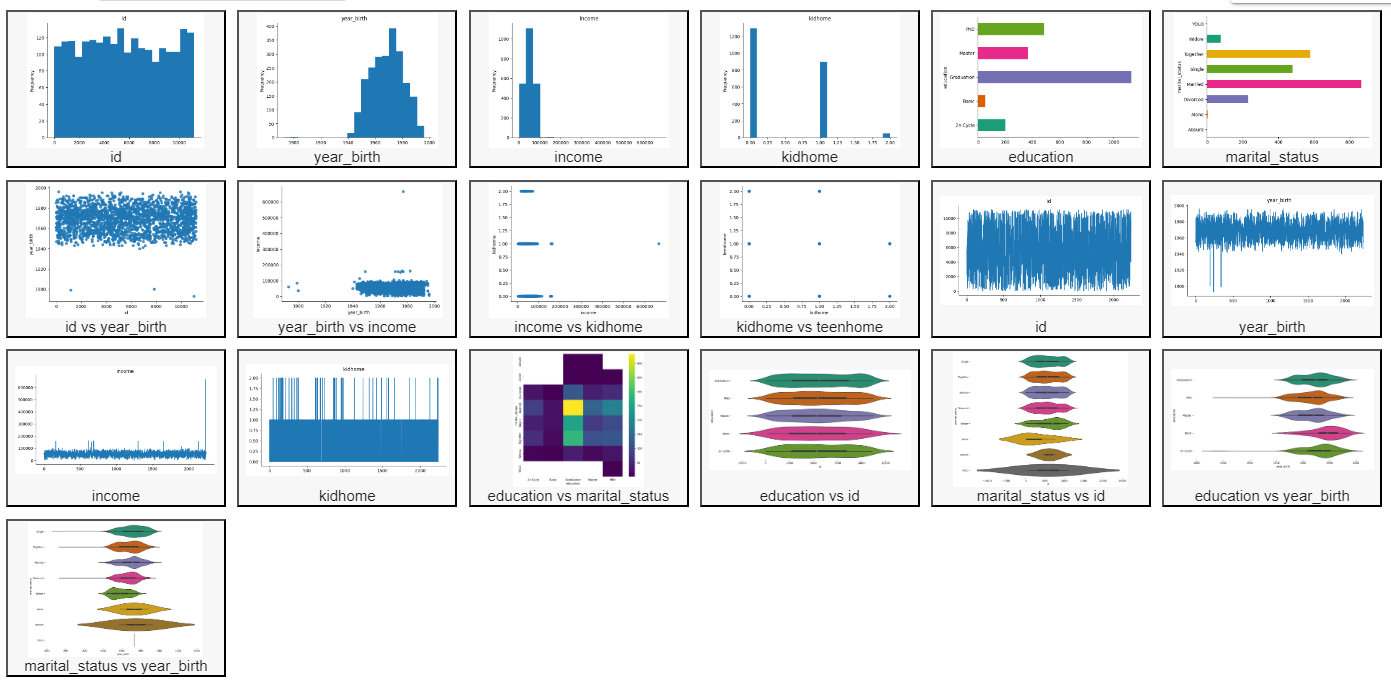

**products**

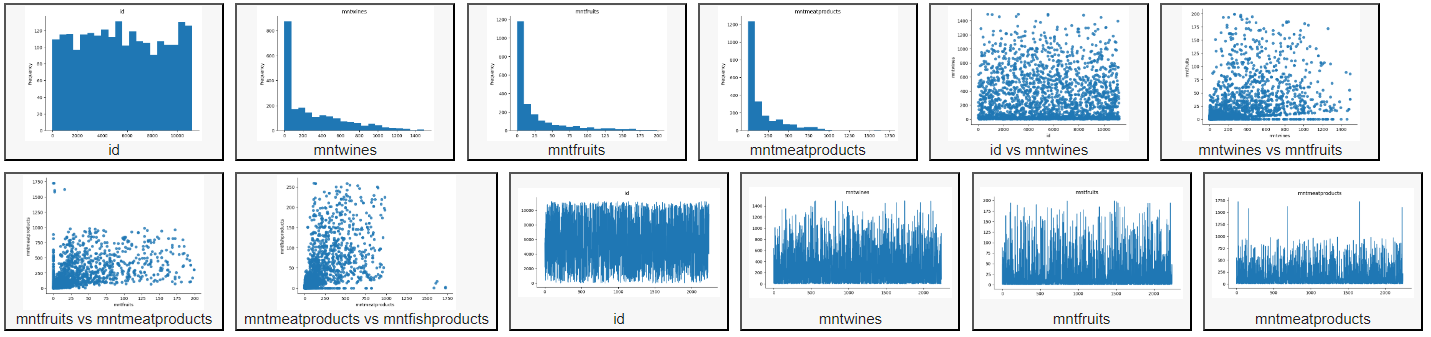

**purchases**

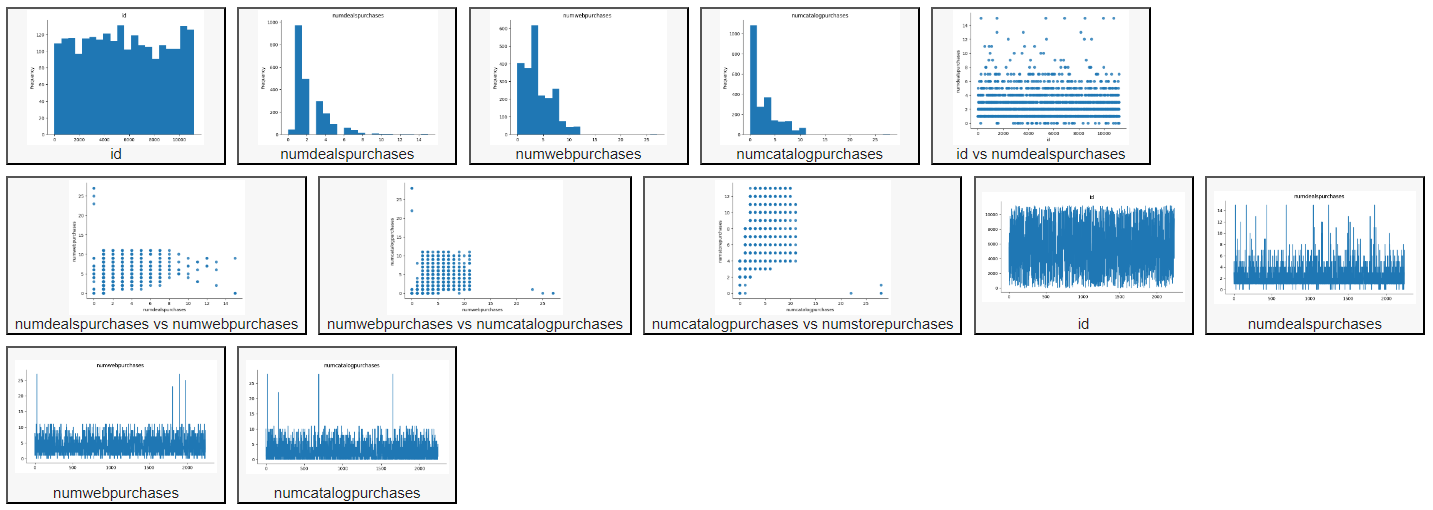

Бесполезные графики:

*   people: id, id vs year_birth, education vs id, marital_status vs id.
*   products: id, id vs mntwines.
*   purchases: id, id vs numdealspurchases

Моя гипотеза:

Я предполагаю, что средний доход клиентов зависит от их уровня образования.

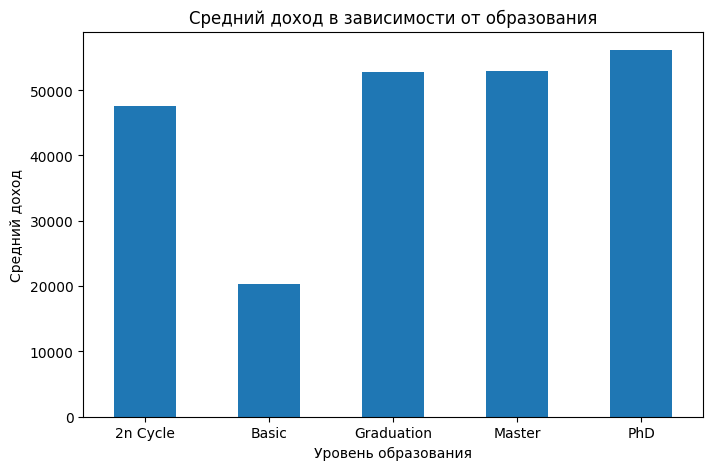

In [ ]:
import matplotlib.pyplot as plt

# считаем средний доход для каждого уровня образования
income_by_education = people.groupby('education')['income'].mean()

# строим график
income_by_education.plot(kind='bar', figsize=(8, 5))

plt.title('Средний доход в зависимости от образования')
plt.xlabel('Уровень образования')
plt.ylabel('Средний доход')
plt.xticks(rotation=0)
plt.show()

## Предобработка данных

Соберём разрозненные таблицы в одну (и порадуемся, что их объём позволяет это сделать). Как мы помним, в данных были пропуски.

In [ ]:
df = pd.merge(pd.merge(people, products, on='id'), purchases, on='id')
df.isna().sum()

,0
id,0
year_birth,0
education,0
marital_status,0
income,24
kidhome,0
teenhome,0
dt_customer,0
recency,0
complain,0


Не все алгоритмы машинного обучения умеют работать с пропусками в данных. Есть несколько стратегий для борьбы с пропусками, самая частая - заполнение пропусков модой, медианой или средним. Если пропусков слишком много, то имеет смысл выбросить соответствующую строку или столбец целиком.

Есть и более продвинутые методы, например kNN (K Nearest Neighbours). Суть данного метода заключается в том, что на основании известных признаков для объекта находятся "соседи", располагающиеся как можно ближе к исходному объекту в пространстве. Затем по этим объектам вычисляется значение недостающего признака.

Возникает два вопроса:

1. Каким образом представить объекты в пространстве?
2. Как считать расстояние между ними?

Ответ на оба — зависит от задачи. Объект обычно проще всего представить как вектор признаков. Для подсчета расстояния используются, например:
- евклидово расстояние и его общий случай (расстояние минковского);
- косинусное расстояние;
- манхэттенское расстояние
- расстояние Чебышёва;
- какое угодно, придуманное вами.

Реализуем kNN для восстановления пропущенных значений `income`. Будем считать евклидово расстояние между векторами. Сначала превратим каждую строку в числовой вектор. Для этого выполним следующие шаги:

* удалим столбец `id`

* проведём one-hot кодирование столбцов `education` и `marital_status`

* проведём нормировку (min-max scaling) столбца `dt_customer`

* проведём нормализацию (z-scaling) полученных векторов, потому что евклидово расстояние чувствительно к размерности признаков

Подумайте, почему именно такие преобразования являются необходимыми.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# объединяем исходные таблицы
df = pd.merge(
    pd.merge(people, products, on='id'),
    purchases,
    on='id'
)

# удаляем id
df = df.drop(columns='id')

# преобразуем дату в числовой формат
df['dt_customer'] = pd.to_datetime(
    df['dt_customer'],
    format='%d-%m-%Y'
).map(pd.Timestamp.toordinal)

# кодируем категориальные признаки
df = pd.get_dummies(
    df,
    columns=['education', 'marital_status'],
    dtype=int
)

# нормируем дату
df[['dt_customer']] = MinMaxScaler().fit_transform(
    df[['dt_customer']]
)

# стандартизируем признаки, не затрагивая income
features = df.drop(columns='income').columns
df[features] = StandardScaler().fit_transform(df[features])

Допишите реализацию kNN.

In [ ]:
import numpy as np
from scipy.spatial import distance


class CustomKNeighborsRegressor:
    def __init__(self, n_neighbors=3):
        # сохраняем количество ближайших соседей
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        # сохраняем обучающие признаки и целевые значения
        self.X = np.asarray(X)
        self.y = np.asarray(y)

    def kneighbors(self, X_test):
        # считаем евклидовы расстояния между объектами
        all_distances = distance.cdist(
            np.asarray(X_test),
            self.X,
            metric='euclidean'
        )

        # выбираем индексы ближайших соседей
        indices = np.argsort(all_distances, axis=1)[:, :self.n_neighbors]

        # оставляем расстояния только до выбранных соседей
        distances = np.take_along_axis(
            all_distances,
            indices,
            axis=1
        )

        return distances, indices


# выделяем строки с известным income
train = df.dropna(subset=['income'])

# выделяем строки с пропущенным income
test = df[df['income'].isna()]

# обучаем собственную модель
custom_knn = CustomKNeighborsRegressor(n_neighbors=3)

custom_knn.fit(
    train.drop(columns='income'),
    train['income']
)

# находим ближайших соседей
distances, indices = custom_knn.kneighbors(
    test.drop(columns='income')
)

In [ ]:
knn = CustomKNeighborsRegressor(n_neighbors=3)
knn.fit(df.dropna().drop(columns='income'), df.dropna())
distances, indices = knn.kneighbors(df[df['income'].isna()].drop(columns='income'))

Если вы всё сделали правильно, то результаты должны совпасть с решением "из коробки", порядок возвращаемых соседей можно не учитывать.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# создаём готовую модель
sklearn_knn = KNeighborsRegressor(n_neighbors=3)

# обучаем модель на тех же данных
sklearn_knn.fit(
    train.drop(columns='income'),
    train['income']
)

# находим ближайших соседей
sklearn_distances, sklearn_indices = sklearn_knn.kneighbors(
    test.drop(columns='income')
)

# сравниваем результаты
print(
    'Расстояния совпадают:',
    np.allclose(distances, sklearn_distances, atol=1e-7)
)

print(
    'Индексы соседей совпадают:',
    np.array_equal(indices, sklearn_indices)
)

Расстояния совпадают: True
Индексы соседей совпадают: False


Заполните пропуски в `income` средним значением по 3 ближайшим соседям.

In [ ]:
# получаем значения income трёх ближайших соседей
neighbor_income = train['income'].to_numpy()[indices]

# считаем среднее значение income соседей
predicted_income = neighbor_income.mean(axis=1)

# заполняем пропуски
df.loc[df['income'].isna(), 'income'] = predicted_income

# проверяем, остались ли пропуски
print(df['income'].isna().sum())

0


In [ ]:
df['income'] = StandardScaler().fit_transform(df[['income']])

## Кластеризация. Методы снижения размерности

In [ ]:
%%capture
!pip install umap-learn

Раз уж мы заговорили про поиск похожих между собой объектов, обсудим также кластеризацию.

[Кластеризация](https://ru.wikipedia.org/wiki/%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%BD%D1%8B%D0%B9_%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7) - это один из видов задач обучения без учителя. Она заключается в разбиении всех объектов на группы похожих между собой объектов и сильно отличающихся от всех остальных. Так как строгого понятия похожести объектов нет, то алгоритмов кластеризации много, а результаты их работы могут сильно зависеть от качества входных данных и подобранных гиперпараметров.

Обсудим один из самых популярных методов кластеризации - [kMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

Идея метода заключается в том, что на каждой итерации пересчитывается центр масс (центроид) для каждого кластера, полученного на предыдущем шаге, затем объекты снова разбиваются на кластеры согласно тому, какой из новых центроидов находится ближе.
Более формально, алгоритм принимает на вход выборку $X_1, \dots, X_N$ и параметр $k$, указывающий необходимое число кластеров. Выходом алгоритма является набор из $k$ центроидов $\{\mu_1, \dots, \mu_k\}$, с помощью которых кластеризация осуществляется путём отнесения каждого объекту к ближайшему центроиду. Все точки внутри одного кластера ближе к центроиду этого кластера, чем к центроиду любого другого кластера.
Метод может быть сформулирован как задача оптимизации, а именно, минимизации суммарного квадратичного отклонения точек кластеров от центров этих кластеров по центроидам и кластерам: $$\sum_{i=1}^k \sum_{X_n \in C_i} ||X_n - \mu_i||^2 \rightarrow \min, \text{где $C_i$ - это $i$-ый кластер, $\mu_i$ - это центр масс кластера $C_i$.}$$
Решение такой задачи оптимизации является NP-трудной задачей, однако существует простой итеративный алгоритм, позволяющий найти локальный минимум указанного функционала. Алгоритм представляет собой последовательное чередование двух шагов до сходимости.
Предположим, что как-то (например, случайно) выбраны начальные положения центроидов $\mu_1, \dots, \mu_k$.

1. Этап кластеризации. На данном этапе происходит кластеризация выборки, как было описано выше: каждый объект относится к кластеру ближайшего к нему центроида. Формально, $$C_i = \{X_n : ||X_n - \mu_i|| \leq ||X_n - \mu_j||, \text{ для всех $j \in \{1, \dots, k\}$}\}.$$

2. Этап обновления центроидов. На данном этапе центроиды пересчитываются, как центры масс только что построенных кластеров. Формально, $$\mu_i = \frac{1}{|C_i|}\sum_{X_n \in C_i} X_n.$$

Этот процесс продолжается, пока центроиды и кластеризация продолжают изменяться. Алгоритм гарантированно сходится, однако не гарантируется достижение глобального минимума, а только одного из локальных минимумов. Другим недостатком алгоритма является то, что итоговая кластеризация зависит от выбора исходных центров кластеров. На практике алгоритм запускается несколько раз из различных начальных приближений, а полученные результаты некоторым образом усредняются. Стоит также отметить, что число кластеров необходимо знать заранее. Существуют различные эвристики, позволяющие выбирать в некотором смысле оптимальное число кластеров.

_определение взято из материалов курса [ODS](https://habrahabr.ru/company/ods/)_


Посмотрим, что будет давать реализация алгоритма "из коробки" на наших данных. Возьмем только данные из таблицы продуктов.


In [ ]:
X = StandardScaler().fit_transform(products.drop(columns='id'))

Сначала нужно определиться с количеством кластеров. Для этого можно воспользоваться "методом локтя" - мы рeшаем задачу кластеризации несколько раз с разным количеством кластеров и выбираем то минимальное количество кластеров, после которого существенного улучшения не происходит. Ориентироваться будем на две метрики - kMeans.inertia_ и Silhouette Score.

**kMeans.inertia_** отражает сумму расстояний от каждой точки до центра ее кластера, возведенных в квадрат. Это значение также известно как сумма внутрикластерных квадратов (Within-Cluster Sum of Squares, WCSS). Математически инерция выражается следующим образом:

$ Inertia = \sum_{i=0}^{n}(min_{\mu_j \in C}(||x_i - \mu_j||^2)) $

Где $x_i$ - это i-й элемент выборки, $\mu_j$ - это центроид кластера $C$, а $||x_i - \mu_j||$ обозначает Евклидово расстояние между точкой $x_i$ и центроидом $\mu_j$. Инерция показывает, насколько плотно группируются объекты внутри кластеров: чем меньше значение инерции, тем ближе объекты находятся к центроидам своих кластеров.

**Silhouette Score** (Силуэт) рассчитывается как разница между средним расстоянием до объектов других кластеров (b) и средним расстоянием до объектов в том же кластере (a), деленная на максимальное из этих значений:

$s = \frac{b - a}{max(a, b)}$

Где $a$ - это среднее расстояние от объекта до других объектов в том же кластере, а $b$ - это минимальное среднее расстояние от объекта до объектов в других кластерах. Значение силуэта лежит в диапазоне от -1 до 1, где высокий положительный счет указывает на то, что объект хорошо соответствует своему кластеру и плохо соответствует соседним кластерам. Обычно, чем выше средний силуэт для всех объектов, тем лучше структурированы кластеры.

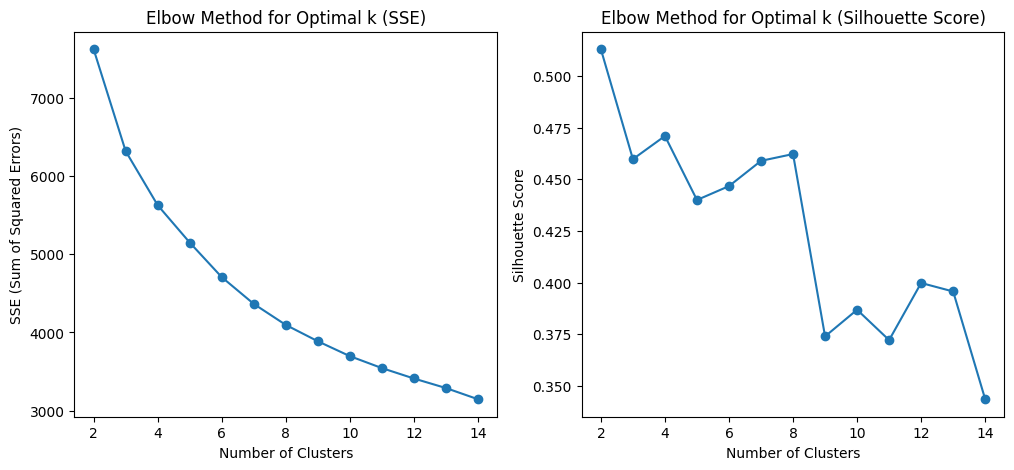

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score


xaxs = list(range(2, 15))
kmeans_kwargs = {
    "init": "k-means++",
    "n_init": 10,
    "random_state": 42,
    "algorithm": "lloyd"
}

silhouette_scores = []
sse = []

for k in xaxs:
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(X)
    sse.append(kmeans.inertia_)

    silhouette_avg = silhouette_score(X, kmeans.labels_)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(12, 5))

# SSE
plt.subplot(1, 2, 1)
plt.plot(xaxs, sse, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('SSE (Sum of Squared Errors)')
plt.title('Elbow Method for Optimal k (SSE)')

# Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(xaxs, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Elbow Method for Optimal k (Silhouette Score)')

plt.show()

4 кластера выглядит хорошо. 8 тоже.

In [ ]:
kmeans = KMeans(n_clusters=4, **kmeans_kwargs)
kmeans.fit(X)
cluster_labels = kmeans.labels_

Посмотрим на то, что получается. 6-мерный вектор будет проблематично отобразить на плоскости, поэтому прибегнем к снижению размерности - переходом в меньшее по количеству измерений признаковое пространство. Рассмотрим три подхода, имеющих реализацию "из коробки" - PCA, t-SNE, UMAP.

**PCA (метод главных компонент)** - это линейный алгоритм, который используется для уменьшения размерности данных путем проекции их на пространство меньшей размерности, сохраняя при этом максимальное количество информации в данных. Это достигается путем определения новых осей (главных компонент), которые направлены в сторону максимальной дисперсии данных. Первая главная компонента имеет наибольшую дисперсию, вторая - максимальную дисперсию среди оставшихся компонент и так далее. Для выбора количества главных компонент часто используют критерий, основанный на объясненной дисперсии, то есть на той доле общей дисперсии, которую объясняют выбранные компоненты.

**t-SNE (Стохастическое вложение соседей с t-распределением)** - это нелинейный алгоритм, который работает на основе вероятностных распределений: в многомерном пространстве данные моделируются так, что похожие объекты имеют высокую вероятность быть "соседями", в то время как непохожие объекты - низкую. Эти вероятности затем используются для определения расположения объектов в пространстве уменьшенной размерности таким образом, чтобы структура данных оставалась похожей. Чем-то напоминает kNN.


**UMAP (Uniform Manifold Approximation and Projection)** - это современный алгоритм уменьшения размерности, который можно считать конкурентом t-SNE. Он также основан на концепции многомерного многообразия, но использует другой математический подход, основанный на топологии. UMAP стремится сохранить глобальную структуру данных, в отличие от t-SNE, который фокусируется больше на локальной.

[Немного красивых картинок](https://habr.com/ru/companies/newprolab/articles/350584/)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


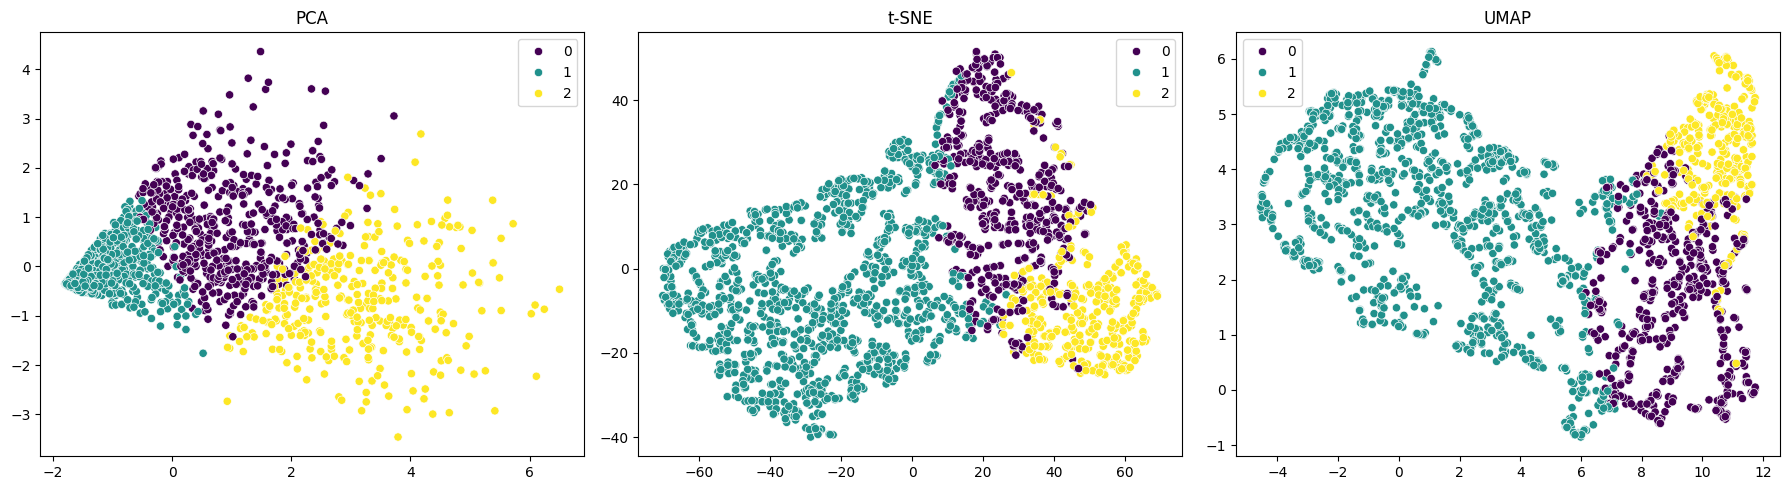

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from umap import UMAP

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X)

pca = PCA(n_components=2)
tsne = TSNE(n_components=2, random_state=42)
umap = UMAP(n_components=2, random_state=42)

pca_result = pca.fit_transform(X)
tsne_result = tsne.fit_transform(X)
umap_result = umap.fit_transform(X)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    x=pca_result[:, 0],
    y=pca_result[:, 1],
    hue=cluster_labels,
    palette='viridis',
    ax=axs[0]
)
axs[0].set_title('PCA')

sns.scatterplot(
    x=tsne_result[:, 0],
    y=tsne_result[:, 1],
    hue=cluster_labels,
    palette='viridis',
    ax=axs[1]
)
axs[1].set_title('t-SNE')

sns.scatterplot(
    x=umap_result[:, 0],
    y=umap_result[:, 1],
    hue=cluster_labels,
    palette='viridis',
    ax=axs[2]
)
axs[2].set_title('UMAP')

plt.tight_layout()
plt.show()

Попробуйте проинтерпретировать получающиеся результаты.

In [ ]:
products['cluster_labels'] = cluster_labels
products['cluster_labels'].value_counts()

2    1297
0     392
3     345
1     206
Name: cluster_labels, dtype: int64

In [ ]:
cluster_means = products.drop(columns='id').groupby('cluster_labels').mean()
cluster_means.style.background_gradient(cmap='Blues', axis=0)  # можно ли сказать, что у нас есть кластер любителей вина?..

,mntwines,mntfruits,mntmeatproducts,mntfishproducts,mntsweetproducts,mntgoldprods
cluster_labels,,,,,,
0,717.056122,35.826531,366.737245,53.158163,35.084184,39.551020
1,475.626214,26.033981,170.776699,32.325243,25.941748,143.601942
2,96.339244,6.353123,35.407864,8.926754,6.353123,17.320740
3,512.460870,90.637681,432.182609,130.382609,96.475362,90.023188


### Задание

В предыдущем пункте работы мы применили готовый код для кластеризации, чтобы увидеть, как она работает. Теперь ваша задача - написать код для реализации алгоритма kMeans самостоятельно (речь, конечно, идет о намного менее, нежели версия "из коробки", оптимизированной версии алгоритма).

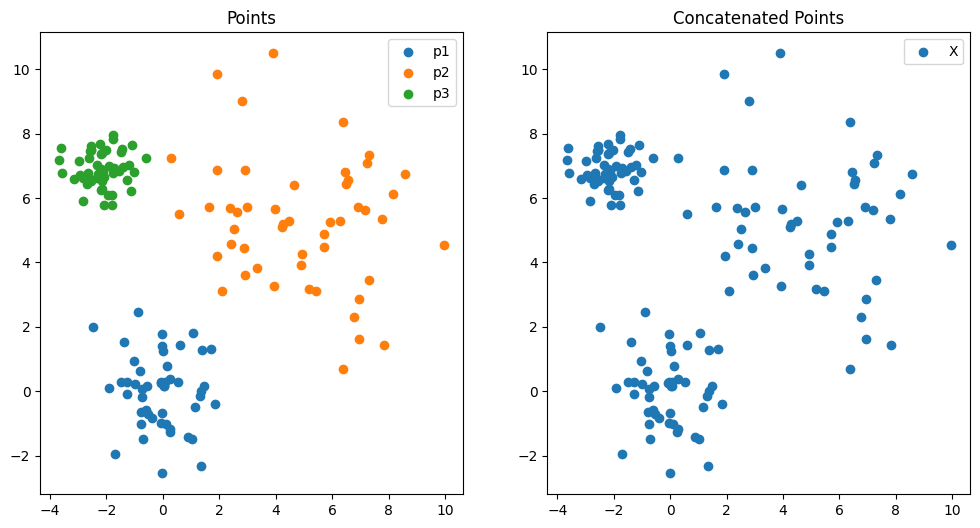

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


p1 = np.random.normal(loc=0, scale=1, size=(50,2))
p2 = np.random.normal(loc=5, scale=2, size=(50,2))
p3 = np.random.normal(loc=3, scale=0.6, size=(50,2)) - np.array([5, -4])
X = np.concatenate((p1, p2, p3))

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].scatter(p1[:, 0], p1[:, 1], label='p1')
axs[0].scatter(p2[:, 0], p2[:, 1], label='p2')
axs[0].scatter(p3[:, 0], p3[:, 1], label='p3')
axs[0].set_title('Points')
axs[0].legend()

axs[1].scatter(X[:, 0], X[:, 1], label='X')
axs[1].set_title('Concatenated Points')
axs[1].legend()

plt.show()

### 1
Напишите функцию, которая рассчитывает расстояния от центров кластеров до каждой точки и возвращает, к какому кластеру принадлежит каждая точка.

In [ ]:
import numpy as np
import scipy
from scipy.spatial.distance import cdist

def kmeans_predict(X, clusters):
    # считаем расстояния от точек до центроидов
    distances = cdist(X, clusters, metric='euclidean')

    # выбираем индекс ближайшего центроида
    labels = np.argmin(distances, axis=1)

    return labels

Посмотрим, что получается.

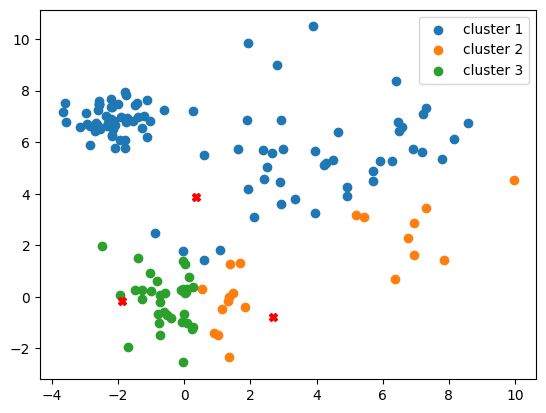

In [ ]:
# случайные координаты для центров кластеров
centroids = np.random.normal(loc=0.0, scale=2., size=6).reshape((3, 2))

labels = kmeans_predict(X, centroids)

plt.scatter(X[labels == 0, 0], X[labels == 0, 1], label='cluster 1')
plt.scatter(X[labels == 1, 0], X[labels == 1, 1], label='cluster 2')
plt.scatter(X[labels == 2, 0], X[labels == 2, 1], label='cluster 3')
plt.plot(centroids[:, 0], centroids[:, 1], 'rX')
plt.legend()
plt.show()

### 2
Напишите код для обновления центров кластеров. Запоминайте центры кластеров для дальнейшей визуализации.

In [ ]:
centroids = np.random.normal(loc=0.0, scale=2., size=6).reshape((3, 2))
k = len(centroids)
centroids_history = [centroids] # история центров кластеров

iters = 7 # количество шагов итерации обновления центров кластеров

for i in range(iters):
    labels = kmeans_predict(X, centroids)

    # пересчитываем центры кластеров
    new_centroids = centroids.copy()

    for j in range(k):
        # выбираем точки текущего кластера
        points = X[labels == j]

        # считаем новый центр, если кластер не пустой
        if len(points) > 0:
            new_centroids[j] = points.mean(axis=0)

    # обновляем центры и сохраняем их историю
    centroids = new_centroids
    centroids_history.append(centroids.copy())

Посмотрим на результат.

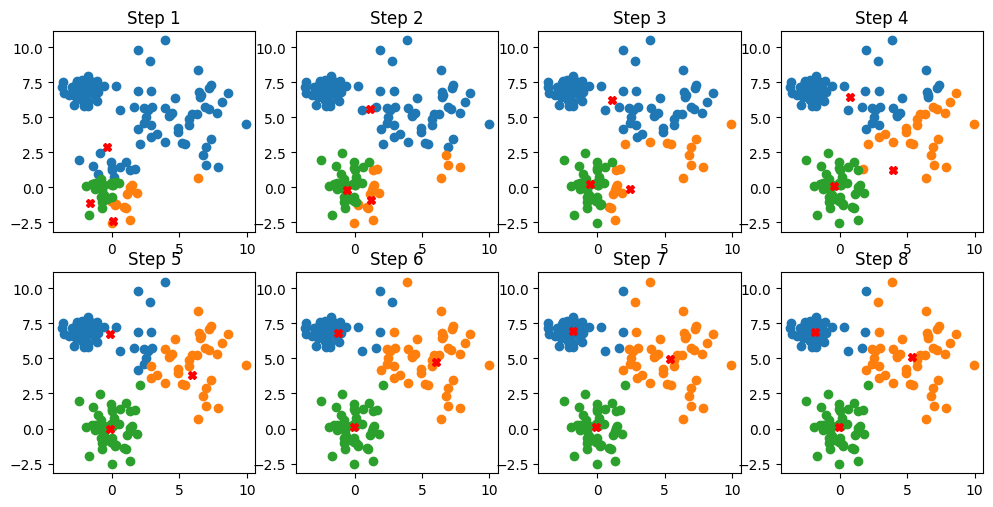

In [ ]:
plt.figure(figsize=(12, 12))

for i in range(iters + 1):
    labels = kmeans_predict(X, centroids_history[i])
    plt.subplot((iters + 1) // 2, (iters + 1) // 2, i + 1)
    plt.scatter(X[labels == 0, 0], X[labels == 0, 1], label='cluster 1')
    plt.scatter(X[labels == 1, 0], X[labels == 1, 1], label='cluster 2')
    plt.scatter(X[labels == 2, 0], X[labels == 2, 1], label='cluster 3')
    plt.plot(centroids_history[i][:, 0], centroids_history[i][:, 1], 'rX')
    # plt.legend()
    plt.title('Step {:}'.format(i + 1))

### 3

Напишите функцию обучения kMeans. Параметры:

* k - кол-во кластеров,
* max_iter - через сколько итераций нужно остановиться,
* tol - если сумма расстояний между прошлыми центрами кластеров и новыми центрами меньше tol (для всех кластеров!), то остановиться,
* low и high - это минимально и максимально значение, которое могут принимать точки центров кластеров при генерации.



Начните с генерации центров кластеров с помощью np.random.uniform. Затем на каждой итерации нужно сделать следующее:
* определить, к какому кластеру относится каждая точка,
* по точкам в кластере пересчитать центр кластера, если точек в кластере нет - сгенерировать новый случайный центр,
* посчитать loss как сумму расстояний (euclidean) между кластерами, полученными на прошлой итерации, и новыми кластерами.

In [ ]:
def kmeans_fit_predict(X, k=8, max_iter=100, tol=0.001,
                       low=0.0, high=1.0, print_progress=False):
    X = np.asarray(X)

    # генерируем начальные центроиды
    clusters = np.random.uniform(low, high, size=(k, X.shape[1]))

    loss_history = []

    for i in range(max_iter):
        # определяем принадлежность точек к кластерам
        labels = kmeans_predict(X, clusters)

        # сохраняем предыдущие центроиды
        old_clusters = clusters.copy()

        # пересчитываем центроиды
        for j in range(k):
            points = X[labels == j]

            if len(points) > 0:
                clusters[j] = points.mean(axis=0)
            else:
                # пустой кластер: генерируем новый случайный центр
                clusters[j] = np.random.uniform(low, high, size=X.shape[1])

        # считаем изменение положения центроидов
        loss = np.sum(np.linalg.norm(clusters - old_clusters, axis=1))
        loss_history.append(loss)

        if print_progress:
            print(f'Итерация = {i}, loss = {loss}')

        # останавливаемся, если изменение центроидов достаточно мало
        if loss < tol:
            break

    # итоговая принадлежность точек к кластерам
    labels = kmeans_predict(X, clusters)

    return clusters, labels, loss_history

Проверим работу функции.

In [ ]:
clusters, labels, loss_history = kmeans_fit_predict(X, k=3, low=0.0, high=np.max(X), print_progress=True)

Итерация = 0, loss = 6.428093276761118
Итерация = 1, loss = 4.184408236427743
Итерация = 2, loss = 0.8822478371879023
Итерация = 3, loss = 0.20006951141162999
Итерация = 4, loss = 0.0


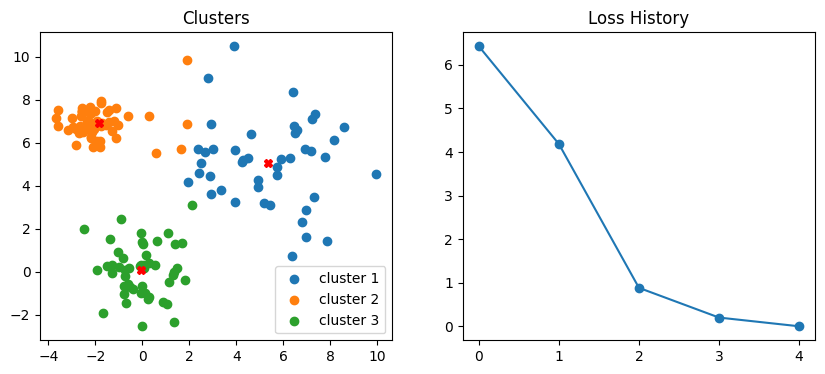

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X[labels == 0, 0], X[labels == 0, 1], label='cluster 1')
plt.scatter(X[labels == 1, 0], X[labels == 1, 1], label='cluster 2')
plt.scatter(X[labels == 2, 0], X[labels == 2, 1], label='cluster 3')
plt.plot(clusters[:, 0], clusters[:, 1], 'rX')
plt.title('Clusters')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss_history, marker='o')
plt.title('Loss History')

plt.show()

В ходе лабораторной работы были освоены основные инструменты анализа и предобработки данных, а также базовые алгоритмы машинного обучения.